# 04. Pemodelan, Evaluasi & Diagnostik Asumsi OLS
**Tujuan:** Melatih dan mengevaluasi model peramalan berbasis regresi pada data uji kronologis (*Out-of-Time* `2019–2023`) melalui *Ablation Study* terstruktur, membandingkan performa terhadap target SMART ($Adj.\ R^2 \ge 0.80$, $\text{RMSE} \le 40$, $\text{MAPE} < 10\%$), menguji 4 asumsi klasik OLS beserta koreksi *Newey-West HAC*, mengeksplorasi model penantang (*Challenger Modeling*), dan menyusun konklusi kebijakan energi.

### Daftar Tugas (*Pipeline Checklist*):
- [x] Memuat matriks fitur `train`/`test` terverifikasi & memeriksa keselarasan metadata
- [x] Menjalankan *Ablation Study* sistematis (`Baseline t` $\rightarrow$ `+ Sector` $\rightarrow$ `+ Sector × t` $\rightarrow$ `+ Month`)
- [x] Menginspeksi ringkasan OLS & menginterpretasikan koefisien domain (`Trillion BTU`)
- [x] Memvalidasi 4 asumsi klasik OLS (`VIF`, *Breusch-Pagan*, *Durbin-Watson/BG*, *Jarque-Bera*) + Mitigasi *Newey-West HAC*
- [x] Memvisualisasikan prediksi *Out-of-Time* (`2019–2023`) & menganalisis error per sektor
- [x] Membangun model penantang (`Sector × t² + Sector × Month`, *Seasonal Naive*, *Holt-Winters ETS*, & `Lag-1/Lag-12 OLS`)
- [x] Menyusun *Master Leaderboard*, mengekspor artefak ke `outputs/`, & merumuskan konklusi

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [81]:
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

In [82]:
PROCESSED_DIR = Path('../data/processed')
FIGURES_DIR = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [83]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
X_train_scaled = pd.read_csv(PROCESSED_DIR / "X_train_scaled.csv")
X_test_scaled = pd.read_csv(PROCESSED_DIR / "X_test_scaled.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Total Renewable Energy"]
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv")["Total Renewable Energy"]

df_clean = pd.read_csv(PROCESSED_DIR / "renewable_clean.csv")
meta_train = df_clean[df_clean["Year"] <= 2018][
    ["Year", "Month", "Sector", "Total Renewable Energy"]
].reset_index(drop=True)
meta_test = df_clean[df_clean["Year"] > 2018][
    ["Year", "Month", "Sector", "Total Renewable Energy"]
].reset_index(drop=True)

In [84]:
assert X_train.shape[0] == len(y_train) == len(meta_train), "Train row alignment mismatch!"
assert X_test.shape[0] == len(y_test) == len(meta_test), "Test row alignment mismatch!"
assert np.allclose(meta_train['Total Renewable Energy'], y_train), "y_train ordering mismatch!"
assert np.allclose(meta_test['Total Renewable Energy'], y_test), "y_test ordering mismatch!"

print(f"Loaded Train: X={X_train.shape}, y={y_train.shape} ({meta_train['Year'].min()}–{meta_train['Year'].max()})")
print(f"Loaded Test : X={X_test.shape},  y={y_test.shape}  ({meta_test['Year'].min()}–{meta_test['Year'].max()})")
print(f"Target min -> Train: {y_train.min():.3f} | Test: {y_test.min():.3f} Trillion BTU (zero-check for MAPE)")

Loaded Train: X=(2208, 18), y=(2208,) (1973–2018)
Loaded Test : X=(240, 18),  y=(240,)  (2019–2023)
Target min -> Train: 0.515 | Test: 16.013 Trillion BTU (zero-check for MAPE)


### 2. *Ablation Study* Sistematis (`Model 1` $\rightarrow$ `Model 4`)
**Tujuan:** Menguji kontribusi setiap kelompok fitur secara bertahap pada data uji masa depan (`2019–2023`) serta menilai pencapaian target SMART ($Test\ Adj.\ R^2 \ge 0.80$, $Test\ RMSE \le 40\text{ Trillion BTU}$, $Test\ MAPE < 10\%$).

In [85]:
def calc_metrics(y_true, y_pred, p):
    r2 = r2_score(y_true,y_pred)
    adj_r2 = 1 - (1 - r2) * (len(y_true) - 1) / (len(y_true) - p - 1)
    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    mae = mean_absolute_error(y_true,y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return r2, adj_r2, rmse, mae, mape

In [86]:
sector_cols = ['Sector_Electric Power', 'Sector_Industrial', 'Sector_Residential']
interaction_cols = ['Sector_Electric Power_x_t', 'Sector_Industrial_x_t', 'Sector_Residential_x_t']
month_cols = [f'Month_{m}' for m in range(2, 13)]

feature_sets = {
    'Model 1: Baseline (t)': ['t'],
    'Model 2: + Sector': ['t'] + sector_cols,
    'Model 3: + Sector x t': ['t'] + sector_cols + interaction_cols,
    'Model 4: + Month (Full)': ['t'] + sector_cols + interaction_cols + month_cols,
}


In [87]:
results = []
fitted_models = {}

for name, cols in feature_sets.items():
    model = LinearRegression()
    model.fit(X_train[cols], y_train)
    fitted_models[name] = model
    prediction = model.predict(X_train[cols])
    tr_r2, tr_adj_r2, tr_rmse, tr_mae, tr_mape = calc_metrics(
        y_train, prediction, len(cols)
    )
    te_r2, te_adj_r2, te_rmse, te_mae, te_mape = calc_metrics(
        y_test, model.predict(X_test[cols]), len(cols)
    )
    results.append(
        {
            "Model": name,
            "Features (p)": len(cols),
            "Train Adj. R²": round(tr_adj_r2, 4),
            "Test R²": round(te_r2, 4),
            "Test Adj. R²": round(te_adj_r2, 4),
            "Test RMSE": round(te_rmse, 2),
            "Test MAE": round(te_mae, 2),
            "Test MAPE (%)": round(te_mape, 2),
            "SMART R² (>=0.80)": te_adj_r2 >= 0.80,
            "SMART RMSE (<=40)": te_rmse <= 40.0,
        }
    )
ablation_df = pd.DataFrame(results)
display(ablation_df)

,Model,Features (p),Train Adj. R²,Test R²,Test Adj. R²,Test RMSE,Test MAE,Test MAPE (%),SMART R² (>=0.80),SMART RMSE (<=40)
0,Model 1: Baseline (t),1,0.0570,-0.0282,-0.0325,98.54,93.22,172.09,False,False
1,Model 2: + Sector,4,0.8752,0.6653,0.6596,56.22,40.26,47.81,False,False
2,Model 3: + Sector x t,7,0.9324,0.8524,0.8479,37.34,23.35,15.83,True,True
3,Model 4: + Month (Full),18,0.9342,0.8544,0.8426,37.08,23.35,16.60,True,True


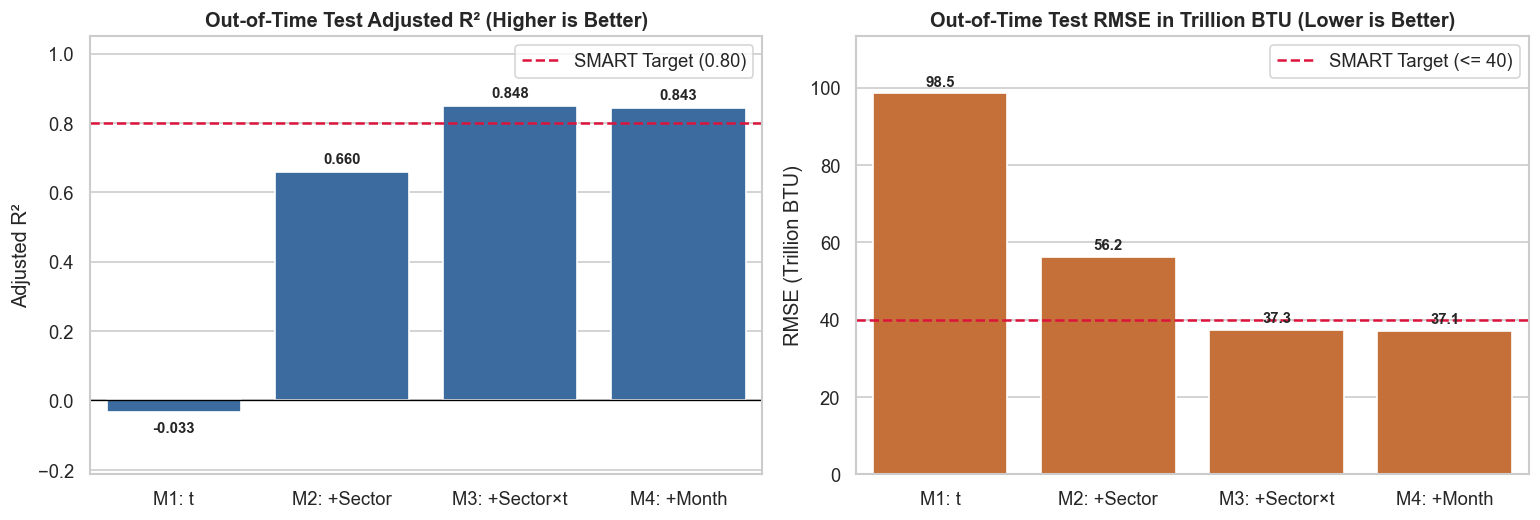

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
short_labels = ['M1: t', 'M2: +Sector', 'M3: +Sector×t', 'M4: +Month']
sns.barplot(x=short_labels, y=ablation_df['Test Adj. R²'], ax=axes[0], color='#2b6cb0')
axes[0].axhline(0.80, color='crimson', linestyle='--', linewidth=1.5, label='SMART Target (0.80)')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_ylim(min(ablation_df['Test Adj. R²'].min() - 0.18, -0.05), 1.05)
axes[0].set_title('Out-of-Time Test Adjusted R² (Higher is Better)', fontweight='bold')
axes[0].set_ylabel('Adjusted R²')
axes[0].legend()
sns.barplot(x=short_labels, y=ablation_df['Test RMSE'], ax=axes[1], color='#dd6b20')
axes[1].axhline(40.0, color='crimson', linestyle='--', linewidth=1.5, label='SMART Target (<= 40)')
axes[1].set_ylim(0, ablation_df['Test RMSE'].max() * 1.15)
axes[1].set_title('Out-of-Time Test RMSE in Trillion BTU (Lower is Better)', fontweight='bold')
axes[1].set_ylabel('RMSE (Trillion BTU)')
axes[1].legend()
for i, v in enumerate(ablation_df['Test Adj. R²']):
    axes[0].text(i, v + (0.025 if v >= 0 else -0.06), f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
for i, v in enumerate(ablation_df['Test RMSE']):
    axes[1].text(i, v + ablation_df['Test RMSE'].max() * 0.02, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_ablation_study.png', dpi=150, bbox_inches='tight')
plt.show()

> **Temuan *Ablation Study* (`Model 1` $\rightarrow$ `Model 4`):**
> - Penambahan fitur secara bertahap membuktikan kontribusi krusial setiap dimensi domain: `Model 1` (`t` saja) gagal menangkap perbedaan skala (`Test Adj. R² = -0.0325`, `RMSE = 98.54`), lalu `+ Sector` melompatkan `Test Adj. R²` ke `0.6596` (`RMSE = 56.22`).
> - Penambahan interaksi **`+ Sector × t`** pada `Model 3` berhasil melampaui dua target awal SMART (**`Test Adj. R² = 0.8479 >= 0.80`**, **`RMSE = 37.34 <= 40`**), sedangkan spesifikasi lengkap **`Model 4 (+ Month)`** memperoleh **`Test R² = 0.8544`**, **`Test Adj. R² = 0.8426`**, dan **`Test RMSE = 37.08 Trillion BTU`**, namun masih menyisakan **`Test MAPE = 16.60%`** (belum memenuhi `<10%`).

### 3. Inferensi Statistik OLS & Interpretasi Koefisien Domain
**Tujuan:** Melatih spesifikasi penuh (`Model 4`) menggunakan `statsmodels.OLS` untuk menelaah signifikansi statistik tiap fitur (*p-value*), uji F simultan, serta menerjemahkan koefisien interaksi menjadi laju pertumbuhan tahunan per sektor (`Trillion BTU / tahun`).

In [89]:
X_train_const = sm.add_constant(X_train, has_constant='add')
X_test_const = sm.add_constant(X_test, has_constant='add')

ols_model = sm.OLS(y_train, X_train_const).fit()
print(ols_model.summary())


                              OLS Regression Results                              
Dep. Variable:     Total Renewable Energy   R-squared:                       0.935
Model:                                OLS   Adj. R-squared:                  0.934
Method:                     Least Squares   F-statistic:                     1742.
Date:                    Sat, 14 Nov 2026   Prob (F-statistic):               0.00
Time:                            21:34:21   Log-Likelihood:                -9287.1
No. Observations:                    2208   AIC:                         1.861e+04
Df Residuals:                        2189   BIC:                         1.872e+04
Df Model:                              18                                         
Covariance Type:                nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

In [90]:
params = ols_model.params
pvals = ols_model.pvalues

sector_growth = pd.DataFrame([
    {'Sector': 'Commercial (Baseline)', 'Monthly Slope (BTU/mo)': params['t'], 'Annual Growth (BTU/yr)': params['t'] * 12},
    {'Sector': 'Electric Power', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Electric Power_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Electric Power_x_t']) * 12},
    {'Sector': 'Industrial', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Industrial_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Industrial_x_t']) * 12},
    {'Sector': 'Residential', 'Monthly Slope (BTU/mo)': params['t'] + params['Sector_Residential_x_t'], 'Annual Growth (BTU/yr)': (params['t'] + params['Sector_Residential_x_t']) * 12},
])

print("\nImplied Linear Growth Trajectory by Sector (1973–2018 Training Fit):")
display(sector_growth.round(4))
non_sig = pvals[pvals >= 0.05]
print(f"\nNon-significant features (p >= 0.05): {list(non_sig.index)}")


Implied Linear Growth Trajectory by Sector (1973–2018 Training Fit):


,Sector,Monthly Slope (BTU/mo),Annual Growth (BTU/yr)
0,Commercial (Baseline),0.0299,0.3589
1,Electric Power,0.2110,2.5322
2,Industrial,0.1644,1.9726
3,Residential,-0.0227,-0.2728



Non-significant features (p >= 0.05): ['const', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_12']


### 4. Diagnostik 4 Asumsi Klasik OLS & Mitigasi *Newey-West HAC*
**Tujuan:** Menguji empat asumsi klasik Gauss-Markov/OLS (Multikolinearitas dengan *VIF*, Homoskedastisitas dengan *Breusch-Pagan*, Autokorelasi dengan *Durbin-Watson* & *Breusch-Godfrey*, serta Normalitas dengan *Jarque-Bera*), memeriksa grafik diagnostik residual, dan menerapkan ***Newey-West HAC robust standard errors*** agar inferensi tetap valid.

In [91]:
resid = ols_model.resid
fitted = ols_model.fittedvalues
X_vif = X_train_const.astype(float)

vif_df = (
    pd.DataFrame(
        {
            "Feature": X_vif.columns[1:],
            "VIF": [
                variance_inflation_factor(X_vif.values, i)
                for i in range(1, X_vif.shape[1])
            ],
        }
    )
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

bp_stat, bp_pval, _, _ = het_breuschpagan(resid, X_vif)

dw_global = durbin_watson(resid)
bg_stat, bg_pval, _, _ = acorr_breusch_godfrey(ols_model, nlags=12)

sector_dw = {}

for sec in sorted(meta_train["Sector"].unique()):
    sec_mask = (meta_train["Sector"] == sec).values
    sector_dw[sec] = round(durbin_watson(resid[sec_mask]), 3)

jb_stat, jb_pval = stats.jarque_bera(resid)

assumptions_summary = pd.DataFrame(
    [
        {
            "Assumption": "1. No Multicollinearity (VIF)",
            "Metric / Test": f"Max VIF = {vif_df['VIF'].max():.2f}",
            "Threshold": "VIF < 5 (or < 10)",
            "Status": "CHECK (Structural)" if vif_df["VIF"].max() >= 5 else "PASS",
        },
        {
            "Assumption": "2. Homoscedasticity",
            "Metric / Test": f"Breusch-Pagan p = {bp_pval:.4e}",
            "Threshold": "p >= 0.05",
            "Status": "PASS" if bp_pval >= 0.05 else "FAIL (Heteroscedastic)",
        },
        {
            "Assumption": "3. No Autocorrelation",
            "Metric / Test": f"BG(12) p = {bg_pval:.4e} | DW = {dw_global:.3f}",
            "Threshold": "p >= 0.05 | DW ~ 2",
            "Status": "PASS" if bg_pval >= 0.05 else "FAIL (Autocorrelated)",
        },
        {
            "Assumption": "4. Normality of Residuals",
            "Metric / Test": f"Jarque-Bera p = {jb_pval:.4e}",
            "Threshold": "p >= 0.05",
            "Status": "PASS" if jb_pval >= 0.05 else "FAIL (Non-Normal)",
        },
    ]
)

C:\Users\micha\AppData\Local\Temp\ipykernel_11056\1738766166.py:22: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_stat, bg_pval, _, _ = acorr_breusch_godfrey(ols_model, nlags=12)


In [92]:
print("=== OLS Classical Assumption Diagnostics ===")
display(assumptions_summary)
print("Within-Sector Durbin-Watson (chronological lag-1 per sector):")
print(sector_dw)

=== OLS Classical Assumption Diagnostics ===


,Assumption,Metric / Test,Threshold,Status
0,1. No Multicollinearity (VIF),Max VIF = 6.48,VIF < 5 (or < 10),CHECK (Structural)
1,2. Homoscedasticity,Breusch-Pagan p = 6.8408e-94,p >= 0.05,FAIL (Heteroscedastic)
2,3. No Autocorrelation,BG(12) p = 0.0000e+00 | DW = 1.542,p >= 0.05 | DW ~ 2,FAIL (Autocorrelated)
3,4. Normality of Residuals,Jarque-Bera p = 1.4746e-40,p >= 0.05,FAIL (Non-Normal)


Within-Sector Durbin-Watson (chronological lag-1 per sector):
{'Commercial': np.float64(1.491), 'Electric Power': np.float64(0.176), 'Industrial': np.float64(0.39), 'Residential': np.float64(0.043)}


In [93]:
print("\nTop 8 Features by VIF:")
display(vif_df.head(8).round(2))
# Remediation: Newey-West HAC robust standard errors for valid inference under Het + Autocorr
ols_hac = sm.OLS(y_train, X_train_const).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
flipped = pd.DataFrame({
    'OLS p-value': ols_model.pvalues.round(4),
    'HAC p-value': ols_hac.pvalues.round(4),
    'Changed Sig (0.05)?': (ols_model.pvalues < 0.05) != (ols_hac.pvalues < 0.05),
})
print(f"\nFeatures whose significance (p < 0.05) changed under Newey-West HAC: {flipped['Changed Sig (0.05)?'].sum()}")
display(flipped[flipped['Changed Sig (0.05)?']] if flipped['Changed Sig (0.05)?'].any() else flipped.head(8))


Top 8 Features by VIF:


,Feature,VIF
0,Sector_Residential_x_t,6.48
1,Sector_Electric Power_x_t,6.48
2,Sector_Industrial_x_t,6.48
3,Sector_Electric Power,5.98
4,Sector_Industrial,5.98
5,Sector_Residential,5.98
6,t,4.00
7,Month_12,1.83



Features whose significance (p < 0.05) changed under Newey-West HAC: 1


,OLS p-value,HAC p-value,Changed Sig (0.05)?
const,0.0879,0.0166,True


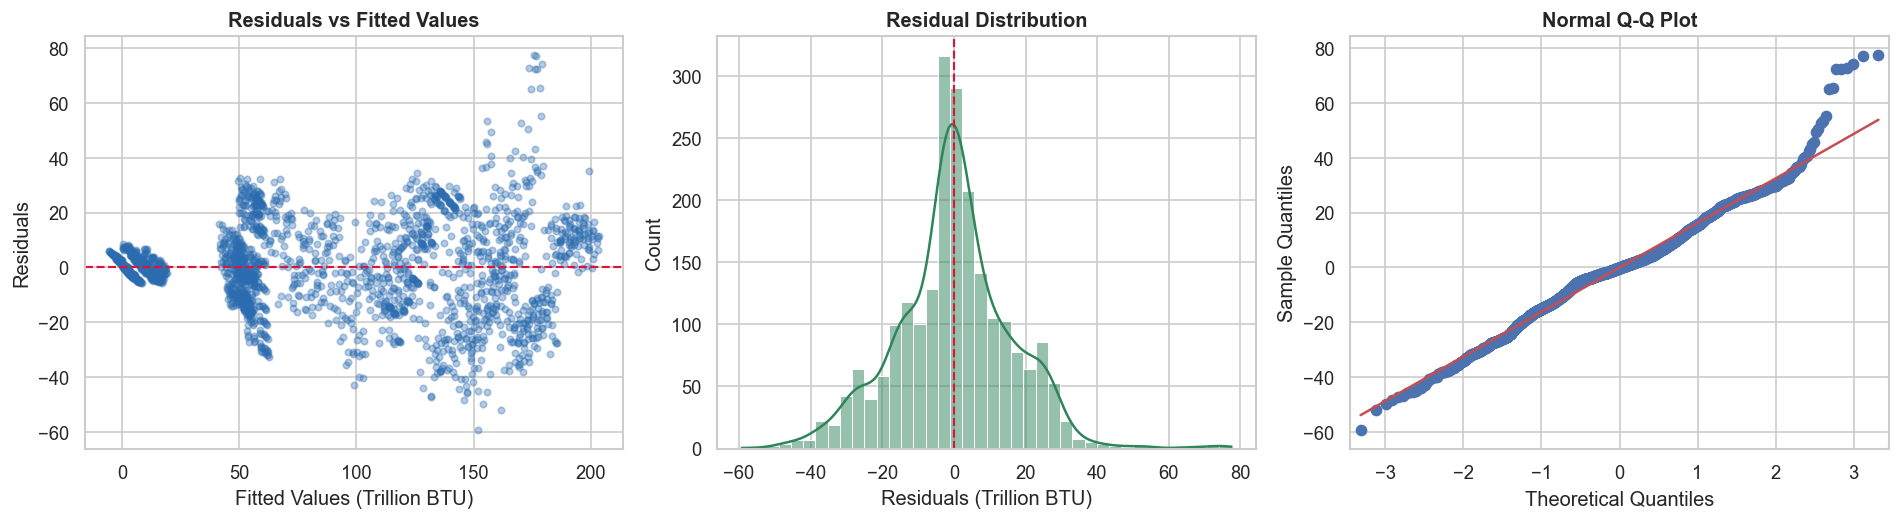

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Residuals vs Fitted (Homoscedasticity & Linearity check)
axes[0].scatter(fitted, resid, alpha=0.35, s=15, color='#2b6cb0')
axes[0].axhline(0, color='crimson', linestyle='--', linewidth=1.3)
axes[0].set_title('Residuals vs Fitted Values', fontweight='bold')
axes[0].set_xlabel('Fitted Values (Trillion BTU)')
axes[0].set_ylabel('Residuals')

# 2. Residual Distribution (Normality check)
sns.histplot(resid, kde=True, bins=40, ax=axes[1], color='#2f855a')
axes[1].axvline(0, color='crimson', linestyle='--', linewidth=1.3)
axes[1].set_title('Residual Distribution', fontweight='bold')
axes[1].set_xlabel('Residuals (Trillion BTU)')

# 3. Normal Q-Q Plot
sm.qqplot(resid, line='s', ax=axes[2])
axes[2].set_title('Normal Q-Q Plot', fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_ols_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

> **Temuan Uji 4 Asumsi Klasik OLS & Koreksi *Newey-West HAC*:**
> - **Multikolinearitas (`Max VIF = 6.48`):** Sedikit melewati `5.0` namun masih `< 10` dan bersifat struktural (berasal dari dummy `Sector` dan interaksi `Sector × t`, sedangkan `t = 4.00` dan seluruh dummy `Month` di bawah `2.0`).
> - **Pelanggaran Asumsi Error:** Terjadi **Heteroskedastisitas** (*Breusch-Pagan* $p = 6.84 \times 10^{-94}$), **Autokorelasi serial kuat** (*Breusch-Godfrey(12)* $p \approx 0$; *Durbin-Watson within-sector* sangat rendah: `Residential = 0.043`, `Electric Power = 0.176`, `Industrial = 0.390`, `Commercial = 1.491`), serta **Non-Normalitas** (*Jarque-Bera* $p = 1.47 \times 10^{-40}$).
> - **Dampak Mitigasi:** *Standard error* `Newey-West HAC` menjaga keabsahan inferensi statistik (contohnya p-value `const` terkoreksi dari `0.0879` menjadi `0.0166`), sekaligus menjelaskan secara diagnostik bahwa regresi linear statis perlu ditingkatkan dengan kelengkungan tren (`t²`), musiman per sektor (`Sector × Month`), atau komponen autokorelasi/deret waktu pada **Langkah 6**.

### 5. Visualisasi Prediksi *Out-of-Time* (`2019–2023`) & Analisis Error per Sektor
**Tujuan:** Memecah error prediksi data uji ($\text{RMSE}$, $\text{MAE}$, $\text{MAPE}$, dan *Mean Bias*) pada masing-masing sektor energi serta memvisualisasikan lintasan `Aktual vs Prediksi OLS` (`2005–2023`) untuk menemukan sumber bias struktural.

In [95]:
train_eval = meta_train.copy()
train_eval['Predicted'] = ols_model.predict(X_train_const).values
train_eval['Split'] = 'Train'

test_eval = meta_test.copy()
test_eval['Predicted'] = ols_model.predict(X_test_const).values
test_eval['Split'] = 'Test'



In [96]:
sector_rows = []

for sec, grp in test_eval.groupby("Sector"):
    y_t = grp["Total Renewable Energy"]
    y_p = grp["Predicted"]
    err = y_t - y_p
    sector_rows.append(
        {
            "Sector": sec,
            "N": len(grp),
            "Mean Actual (BTU)": round(y_t.mean(), 2),
            "Mean Pred (BTU)": round(y_p.mean(), 2),
            "Mean Bias (Act - Pred)": round(err.mean(), 2),
            "MAE (BTU)": round(mean_absolute_error(y_t, y_p), 2),
            "RMSE (BTU)": round(np.sqrt(mean_squared_error(y_t, y_p)), 2),
            "MAPE (%)": round(np.mean(np.abs(err / y_t)) * 100, 2),
        }
    )
sector_error_df = pd.DataFrame(sector_rows).sort_values('RMSE (BTU)', ascending=False).reset_index(drop=True)
sector_error_df.head(10)

,Sector,N,Mean Actual (BTU),Mean Pred (BTU),Mean Bias (Act - Pred),MAE (BTU),RMSE (BTU),MAPE (%)
0,Electric Power,60,251.91,183.94,67.97,67.97,71.49,26.39
1,Industrial,60,194.22,206.33,-12.11,13.08,15.95,6.97
2,Residential,60,53.27,45.99,7.28,8.70,10.71,15.25
3,Commercial,60,20.00,16.92,3.08,3.64,4.49,17.78


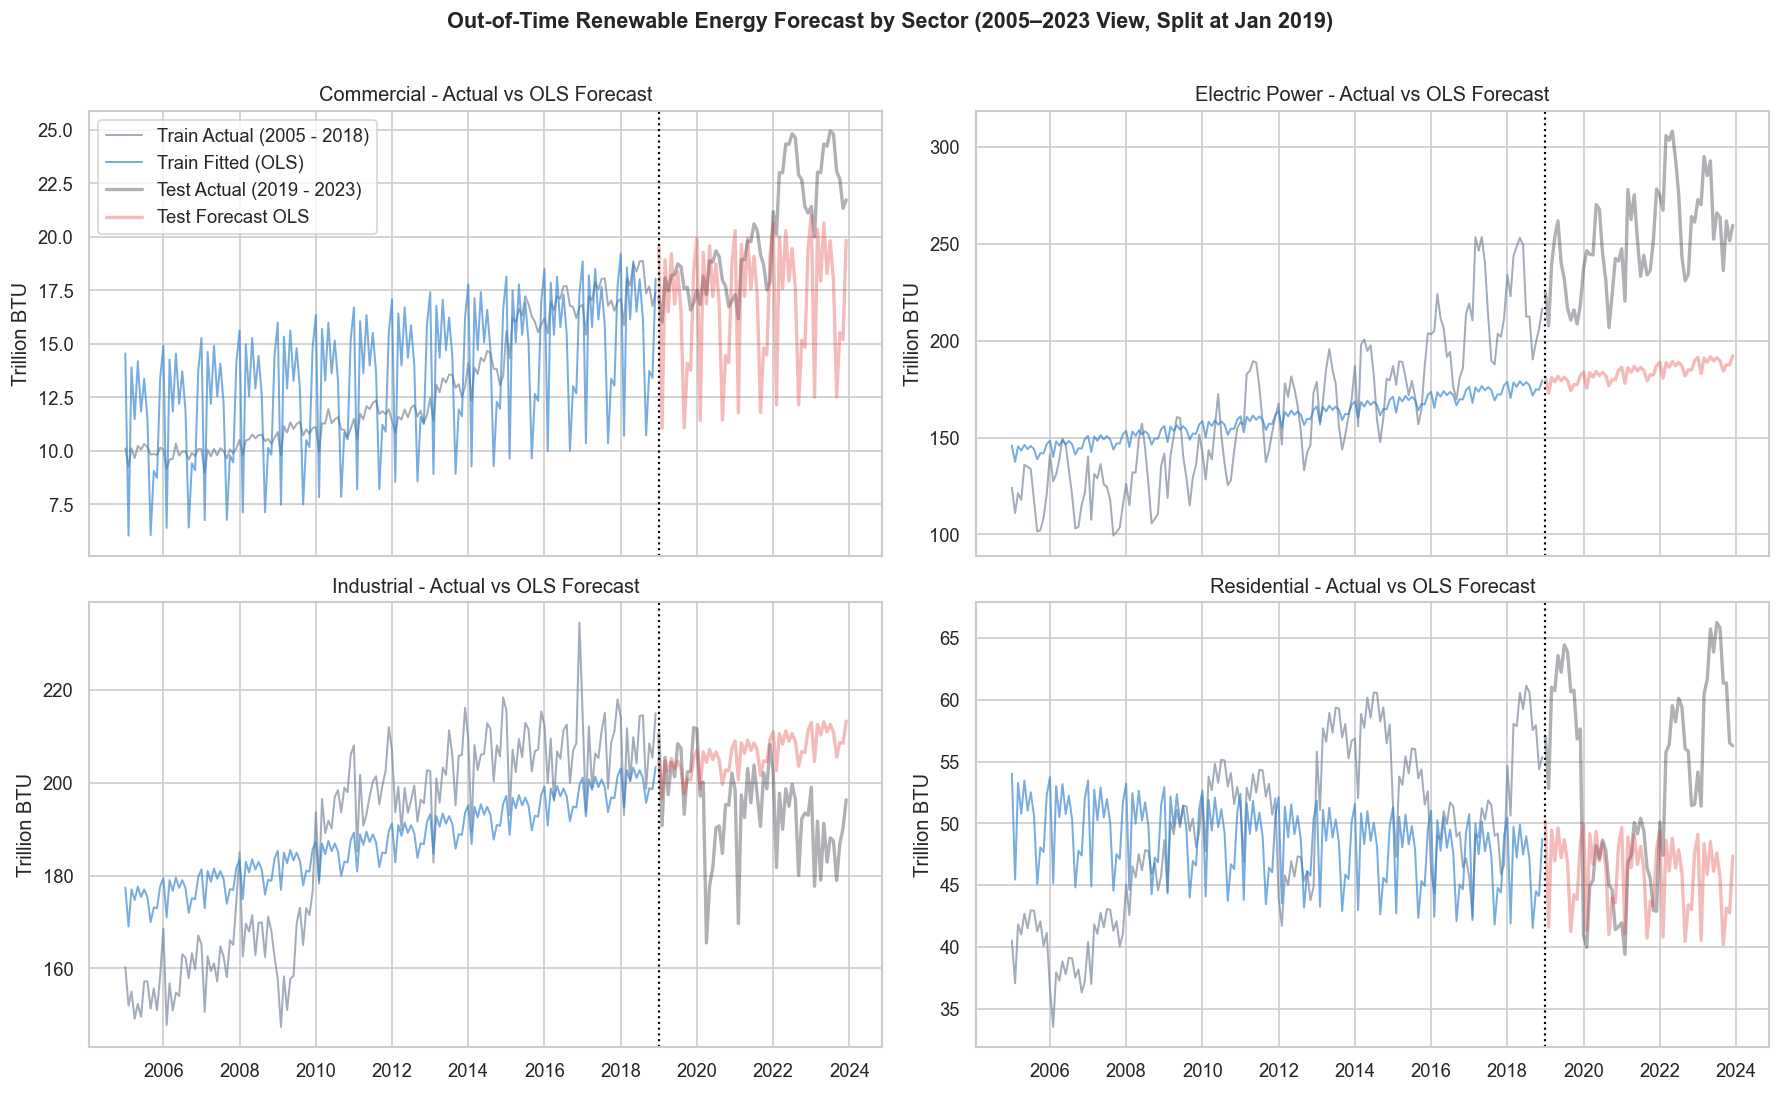

In [97]:
full_eval = pd.concat([train_eval, test_eval], ignore_index=True)
full_eval["Date"] = pd.to_datetime(
    dict(year=full_eval["Year"], month=full_eval["Month"], day=1)
)
plot_df = full_eval[full_eval["Year"] >= 2005].copy()

sectors = sorted(plot_df["Sector"].unique())
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
axes = axes.flatten()

for ax, sec in zip(axes, sectors):
    sub = plot_df[plot_df["Sector"] == sec].sort_values("Date")
    sub_tr = sub[sub["Split"] == "Train"]
    sub_te = sub[sub["Split"] == "Test"]

    # Recent training context (2005–2018)
    ax.plot(
        sub_tr["Date"],
        sub_tr["Total Renewable Energy"],
        alpha=0.65,
        linewidth=1.2,
        color='#718096',
        label="Train Actual (2005 - 2018)",
    )
    ax.plot(
        sub_tr["Date"],
        sub_tr["Predicted"],
        alpha=0.65,
        linewidth=1.2,
        color='#3182ce',
        label="Train Fitted (OLS)",
    )

    # Out-of-Time forecast horizon (2019-2023)
    ax.plot(
        sub_te["Date"],
        sub_te["Total Renewable Energy"],
        alpha=0.35,
        linewidth=2.0,
        color='#1a202c',
        label="Test Actual (2019 - 2023)",
    )
    ax.plot(
        sub_te["Date"],
        sub_te["Predicted"],
        alpha=0.35,
        color='#e53e3e',
        linewidth=2.0,
        label="Test Forecast OLS",
    )

    ax.axvline(pd.Timestamp("2019-01-01"), color="black", linestyle=":", linewidth=1.3)
    ax.set_title(f"{sec} - Actual vs OLS Forecast")
    ax.set_ylabel("Trillion BTU")

    if ax is axes[0]:
        ax.legend(loc="upper left")

fig.suptitle(
    "Out-of-Time Renewable Energy Forecast by Sector (2005–2023 View, Split at Jan 2019)",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_forecast_by_sector.png", dpi=150, bbox_inches="tight")
plt.show()

> **Temuan Analisis Error per Sektor (`Model 4` pada Data Uji `2019–2023`):**
> - Sumber kegagalan utama target `MAPE < 10%` berada di sektor **`Electric Power`** dengan **`Mean Bias = +67.97 Trillion BTU`** (model memprediksi rata-rata `183.94` padahal aktualnya **`251.91 Trillion BTU`**, `RMSE = 71.49`, **`MAPE = 26.39%`**) akibat akselerasi non-linear pembangkit angin & surya yang tidak tertangkap garis tren lurus `1973–2018`.
> - Sektor **`Commercial`** juga mengalami *under-prediction* relatif (`MAPE = 17.78%` karena basis nilainya kecil, `~20.00 Trillion BTU`), dan **`Residential`** memiliki **`MAPE = 15.25%`**, sementara sektor **`Industrial`** sudah melampaui target SMART sejak `Model 4` (**`MAPE = 6.97%`**, `RMSE = 15.95`).

### 6. Model Penantang (*Challenger Modeling*): OLS Non-Linear, Musiman Spesifik-Sektor & *Time-Series ETS*
**Tujuan:** Mengatasi kelemahan struktural `Model 4` (asumsi efek bulan seragam dan tren garis lurus sejak 1973) dengan menerapkan rekomendasi *Data Preparation*: interaksi `Sector × Month`, kelengkungan kuadratik `Sector × t_z²` (`Model 5`), pembanding *Seasonal Naive*, serta *Holt-Winters Exponential Smoothing* per sektor (`Model 6`) untuk mengecek apakah ada model yang menembus $\text{MAPE} < 10\%$.

In [98]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Standardize time index 't' strictly on Train before squaring (prevents collinearity & scale explosion)
t_mean = X_train['t'].mean()
t_std = X_train['t'].std(ddof=0)


def build_m5_features(meta_df, t_series):
    """Build Improved OLS matrix: Sector x (t_z, t_z^2) + Sector x Month."""
    t_z = pd.Series((t_series.values - t_mean) / t_std, index=meta_df.index)
    t_z2 = t_z ** 2

    sec_cats = ['Commercial', 'Electric Power', 'Industrial', 'Residential']
    mon_cats = list(range(1, 13))

    sec_dummies = pd.get_dummies(
        pd.Series(pd.Categorical(meta_df['Sector'], categories=sec_cats), index=meta_df.index),
        prefix='Sector', drop_first=True, dtype=int
    )
    mon_dummies = pd.get_dummies(
        pd.Series(pd.Categorical(meta_df['Month'], categories=mon_cats), index=meta_df.index),
        prefix='Month', drop_first=True, dtype=int
    )

    sec_tz = sec_dummies.multiply(t_z, axis=0)
    sec_tz.columns = [f"{c}_x_tz" for c in sec_dummies.columns]

    sec_tz2 = sec_dummies.multiply(t_z2, axis=0)
    sec_tz2.columns = [f"{c}_x_tz2" for c in sec_dummies.columns]

    # Sector x Month interaction: separate seasonal curve per sector
    sec_mon_parts = []
    for sc in sec_dummies.columns:
        block = mon_dummies.multiply(sec_dummies[sc], axis=0)
        block.columns = [f"{sc}_x_{mc}" for mc in mon_dummies.columns]
        sec_mon_parts.append(block)

    return pd.concat(
        [pd.DataFrame({'t_z': t_z, 't_z2': t_z2}, index=meta_df.index),
         sec_dummies, sec_tz, sec_tz2, mon_dummies] + sec_mon_parts,
        axis=1
    )


# 1. Seasonal Naive Baseline (repeat 2018 monthly pattern across 2019–2023)
naive_lookup = meta_train[meta_train['Year'] == 2018].set_index(['Sector', 'Month'])['Total Renewable Energy']
pred_naive = meta_test.set_index(['Sector', 'Month']).index.map(naive_lookup).to_numpy()

# 2. Model 5: Improved OLS
X_train_m5 = build_m5_features(meta_train, X_train['t'])
X_test_m5 = build_m5_features(meta_test, X_test['t'])
m5_ols = sm.OLS(y_train, sm.add_constant(X_train_m5, has_constant='add')).fit()
pred_m5 = m5_ols.predict(sm.add_constant(X_test_m5, has_constant='add')).values

# 3. Model 6: Per-Sector Holt-Winters Exponential Smoothing (multi-step 60-month forecast)
pred_hw = np.zeros(len(meta_test))
for sec in sorted(meta_train['Sector'].unique()):
    tr_mask = (meta_train['Sector'] == sec).values
    te_mask = (meta_test['Sector'] == sec).values

    y_sec_tr = meta_train.loc[tr_mask, 'Total Renewable Energy'].values
    dates_tr = pd.date_range('1973-01-01', periods=len(y_sec_tr), freq='MS')

    hw_fit = ExponentialSmoothing(
        pd.Series(y_sec_tr, index=dates_tr),
        trend='add',
        damped_trend=True,
        seasonal='mul',
        seasonal_periods=12,
        initialization_method='estimated',
    ).fit(optimized=True)

    pred_hw[te_mask] = hw_fit.forecast(steps=te_mask.sum()).values

# Unified Out-of-Time Comparison (2019–2023)
preds_test = {
    'Seasonal Naive (2018 Repeat)': pred_naive,
    'Model 4: Baseline OLS': ols_model.predict(X_test_const).values,
    'Model 5: Improved OLS (Sec×t² + Sec×Mo)': pred_m5,
    'Model 6: Per-Sector Holt-Winters': pred_hw,
}

comp_rows = []
for name, y_p in preds_test.items():
    err = y_test - y_p
    comp_rows.append({
        'Model': name,
        'Test R²': round(r2_score(y_test, y_p), 4),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, y_p)), 2),
        'Test MAE': round(mean_absolute_error(y_test, y_p), 2),
        'Test MAPE (%)': round(np.mean(np.abs(err / y_test)) * 100, 2),
        'SMART MAPE (<10%)': (np.mean(np.abs(err / y_test)) * 100) < 10.0,
    })

challenger_df = pd.DataFrame(comp_rows)
print("=== Out-of-Time Model Comparison (2019–2023) ===")
display(challenger_df)

# Sector-level MAPE breakdown across models
sec_mape_rows = []
for sec in sorted(meta_test['Sector'].unique()):
    mask = (meta_test['Sector'] == sec).values
    row = {'Sector': sec}
    for name, y_p in preds_test.items():
        short = name.split(':')[0] if ':' in name else 'Seasonal Naive'
        row[f'{short} MAPE (%)'] = round(np.mean(np.abs((y_test[mask] - y_p[mask]) / y_test[mask])) * 100, 2)
    sec_mape_rows.append(row)

print("\n=== Test MAPE (%) by Sector Across Challengers ===")
display(pd.DataFrame(sec_mape_rows))

=== Out-of-Time Model Comparison (2019–2023) ===


,Model,Test R²,Test RMSE,Test MAE,Test MAPE (%),SMART MAPE (<10%)
0,Seasonal Naive (2018 Repeat),0.9595,19.56,12.86,10.58,False
1,Model 4: Baseline OLS,0.8544,37.08,23.35,16.60,False
2,Model 5: Improved OLS (Sec×t² + Sec×Mo),0.9419,23.42,17.03,15.54,False
3,Model 6: Per-Sector Holt-Winters,0.9491,21.93,14.00,10.59,False



=== Test MAPE (%) by Sector Across Challengers ===


,Sector,Seasonal Naive MAPE (%),Model 4 MAPE (%),Model 5 MAPE (%),Model 6 MAPE (%)
0,Commercial,10.59,17.78,17.04,9.26
1,Electric Power,11.31,26.39,14.53,13.57
2,Industrial,7.04,6.97,7.16,6.51
3,Residential,13.40,15.25,23.44,13.05


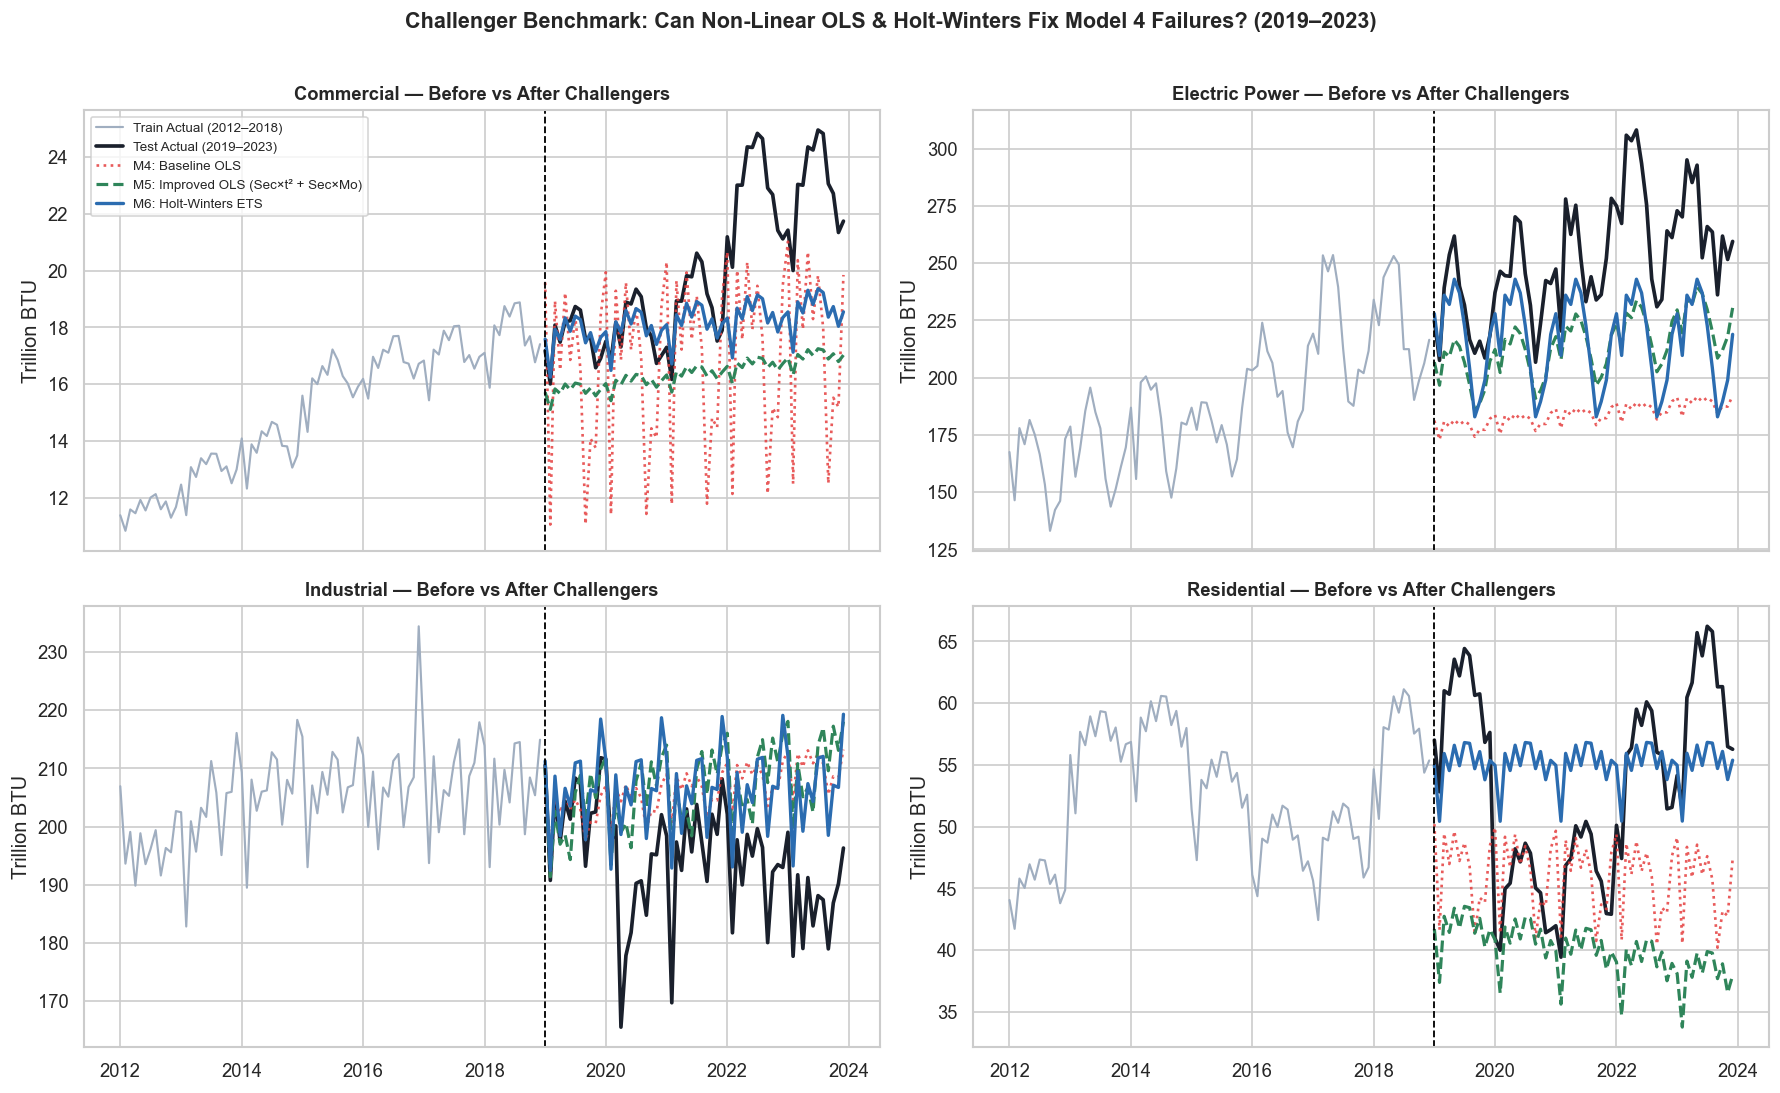

In [99]:
# Compare Actual vs Model 4 (Before) vs Model 5 & Model 6 (After) from 2012 to 2023
hist_df = meta_train[meta_train['Year'] >= 2012].copy()
hist_df['Date'] = pd.to_datetime(dict(year=hist_df['Year'], month=hist_df['Month'], day=1))

te_comp = meta_test.copy()
te_comp['Date'] = pd.to_datetime(dict(year=te_comp['Year'], month=te_comp['Month'], day=1))
te_comp['M4_OLS'] = preds_test['Model 4: Baseline OLS']
te_comp['M5_OLS'] = preds_test['Model 5: Improved OLS (Sec×t² + Sec×Mo)']
te_comp['M6_HW'] = preds_test['Model 6: Per-Sector Holt-Winters']

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for ax, sec in zip(axes.flatten(), sorted(te_comp['Sector'].unique())):
    h = hist_df[hist_df['Sector'] == sec].sort_values('Date')
    t = te_comp[te_comp['Sector'] == sec].sort_values('Date')

    ax.plot(h['Date'], h['Total Renewable Energy'], color='#a0aec0', linewidth=1.3, label='Train Actual (2012–2018)')
    ax.plot(t['Date'], t['Total Renewable Energy'], color='#1a202c', linewidth=2.2, label='Test Actual (2019–2023)')
    ax.plot(t['Date'], t['M4_OLS'], color='#e53e3e', linestyle=':', linewidth=1.6, alpha=0.85, label='M4: Baseline OLS')
    ax.plot(t['Date'], t['M5_OLS'], color='#2f855a', linestyle='--', linewidth=1.9, label='M5: Improved OLS (Sec×t² + Sec×Mo)')
    ax.plot(t['Date'], t['M6_HW'], color='#2b6cb0', linestyle='-', linewidth=2.0, label='M6: Holt-Winters ETS')

    ax.axvline(pd.Timestamp('2019-01-01'), color='black', linestyle='--', linewidth=1.1)
    ax.set_title(f"{sec} — Before vs After Challengers", fontweight='bold', fontsize=11)
    ax.set_ylabel('Trillion BTU')

    if ax is axes[0, 0]:
        ax.legend(loc='upper left', fontsize=8, frameon=True)

fig.suptitle('Challenger Benchmark: Can Non-Linear OLS & Holt-Winters Fix Model 4 Failures? (2019–2023)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_challenger_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

#### 6b. Penyempurnaan Model: *Auto-AIC Holt-Winters* (Horizon 5 Tahun) & Regresi Operasional *Lag* (1 Bulan ke Depan)
**Tujuan:** Menguji apakah pemilihan otomatis komponen tren *damped vs. undamped* berbasis **AIC** pada data latih mampu mendorong akurasi *Holt-Winters* 5 tahun (`Model 6b`) mendekati $\text{MAPE} < 10\%$, sekaligus mengevaluasi skenario peramalan operasional **1 bulan ke depan** menggunakan regresi berbasis fitur historis `lag_1`, `lag_12`, dan `ma_12` (`Model 7`).

In [100]:
# 1. Model 6b: Auto-AIC Holt-Winters (select damped vs undamped strictly on Train AIC)
pred_hw_aic = np.zeros(len(meta_test))
chosen_specs = {}

for sec in sorted(meta_train['Sector'].unique()):
    tr_mask = (meta_train['Sector'] == sec).values
    te_mask = (meta_test['Sector'] == sec).values
    y_sec_tr = pd.Series(
        meta_train.loc[tr_mask, 'Total Renewable Energy'].values,
        index=pd.date_range('1973-01-01', periods=tr_mask.sum(), freq='MS')
    )
    candidates = {
        damped: ExponentialSmoothing(
            y_sec_tr, trend='add', damped_trend=damped,
            seasonal='mul', seasonal_periods=12, initialization_method='estimated'
        ).fit(optimized=True)
        for damped in [False, True]
    }
    best_damped = min(candidates, key=lambda d: candidates[d].aic)
    chosen_specs[sec] = 'Damped' if best_damped else 'Undamped'
    pred_hw_aic[te_mask] = candidates[best_damped].forecast(steps=te_mask.sum()).values

# 2. Model 7: 1-Month-Ahead Operational Regression (lag_1, lag_12, ma_12)
df_lag = df_clean[['Year', 'Month', 'Sector', 'Total Renewable Energy']].sort_values(['Sector', 'Year', 'Month']).copy()
df_lag['lag_1'] = df_lag.groupby('Sector')['Total Renewable Energy'].shift(1)
df_lag['lag_12'] = df_lag.groupby('Sector')['Total Renewable Energy'].shift(12)
df_lag['ma_12'] = df_lag.groupby('Sector')['Total Renewable Energy'].transform(lambda s: s.shift(1).rolling(12).mean())
df_lag = df_lag.dropna().reset_index(drop=True)

X_lag_all = pd.get_dummies(
    df_lag[['lag_1', 'lag_12', 'ma_12', 'Sector', 'Month']],
    columns=['Sector', 'Month'], drop_first=True, dtype=int
)
tr_idx = df_lag['Year'] <= 2018
te_idx = df_lag['Year'] > 2018

m7_lag = sm.OLS(df_lag.loc[tr_idx, 'Total Renewable Energy'], sm.add_constant(X_lag_all.loc[tr_idx], has_constant='add')).fit()
pred_m7 = m7_lag.predict(sm.add_constant(X_lag_all.loc[te_idx], has_constant='add')).values
y_m7_test = df_lag.loc[te_idx, 'Total Renewable Energy'].values

# Compare results clearly separated by forecast horizon
summary_6b = pd.DataFrame([
    {
        'Model': 'Model 6b: Auto-AIC Holt-Winters',
        'Horizon': '5-Year Blind (60-step)',
        'Test R²': round(r2_score(y_test, pred_hw_aic), 4),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_test, pred_hw_aic)), 2),
        'Test MAPE (%)': round(np.mean(np.abs((y_test - pred_hw_aic) / y_test)) * 100, 2),
        'SMART MAPE (<10%)': (np.mean(np.abs((y_test - pred_hw_aic) / y_test)) * 100) < 10.0,
    },
    {
        'Model': 'Model 7: Lag-1/Lag-12 OLS',
        'Horizon': '1-Month Ahead (Operational)',
        'Test R²': round(r2_score(y_m7_test, pred_m7), 4),
        'Test RMSE': round(np.sqrt(mean_squared_error(y_m7_test, pred_m7)), 2),
        'Test MAPE (%)': round(np.mean(np.abs((y_m7_test - pred_m7) / y_m7_test)) * 100, 2),
        'SMART MAPE (<10%)': (np.mean(np.abs((y_m7_test - pred_m7) / y_m7_test)) * 100) < 10.0,
    }
])

print("Auto-AIC Trend Selection per Sector (Train 1973–2018):", chosen_specs)
display(summary_6b)

# Per-sector MAPE for Model 6b & Model 7
sec_6b = []
for sec in sorted(meta_test['Sector'].unique()):
    m_te = (meta_test['Sector'] == sec).values
    m_lag = (df_lag.loc[te_idx, 'Sector'] == sec).values
    sec_6b.append({
        'Sector': sec,
        'M6b Auto-AIC HW MAPE (%)': round(np.mean(np.abs((y_test[m_te] - pred_hw_aic[m_te]) / y_test[m_te])) * 100, 2),
        'M7 1-Mo Lag OLS MAPE (%)': round(np.mean(np.abs((y_m7_test[m_lag] - pred_m7[m_lag]) / y_m7_test[m_lag])) * 100, 2),
    })
display(pd.DataFrame(sec_6b))

Auto-AIC Trend Selection per Sector (Train 1973–2018): {'Commercial': 'Undamped', 'Electric Power': 'Undamped', 'Industrial': 'Undamped', 'Residential': 'Damped'}


,Model,Horizon,Test R²,Test RMSE,Test MAPE (%),SMART MAPE (<10%)
0,Model 6b: Auto-AIC Holt-Winters,5-Year Blind (60-step),0.9621,18.92,10.10,False
1,Model 7: Lag-1/Lag-12 OLS,1-Month Ahead (Operational),0.9925,8.41,5.97,True


,Sector,M6b Auto-AIC HW MAPE (%),M7 1-Mo Lag OLS MAPE (%)
0,Commercial,8.28,10.55
1,Electric Power,10.45,4.38
2,Industrial,8.63,2.64
3,Residential,13.05,6.30


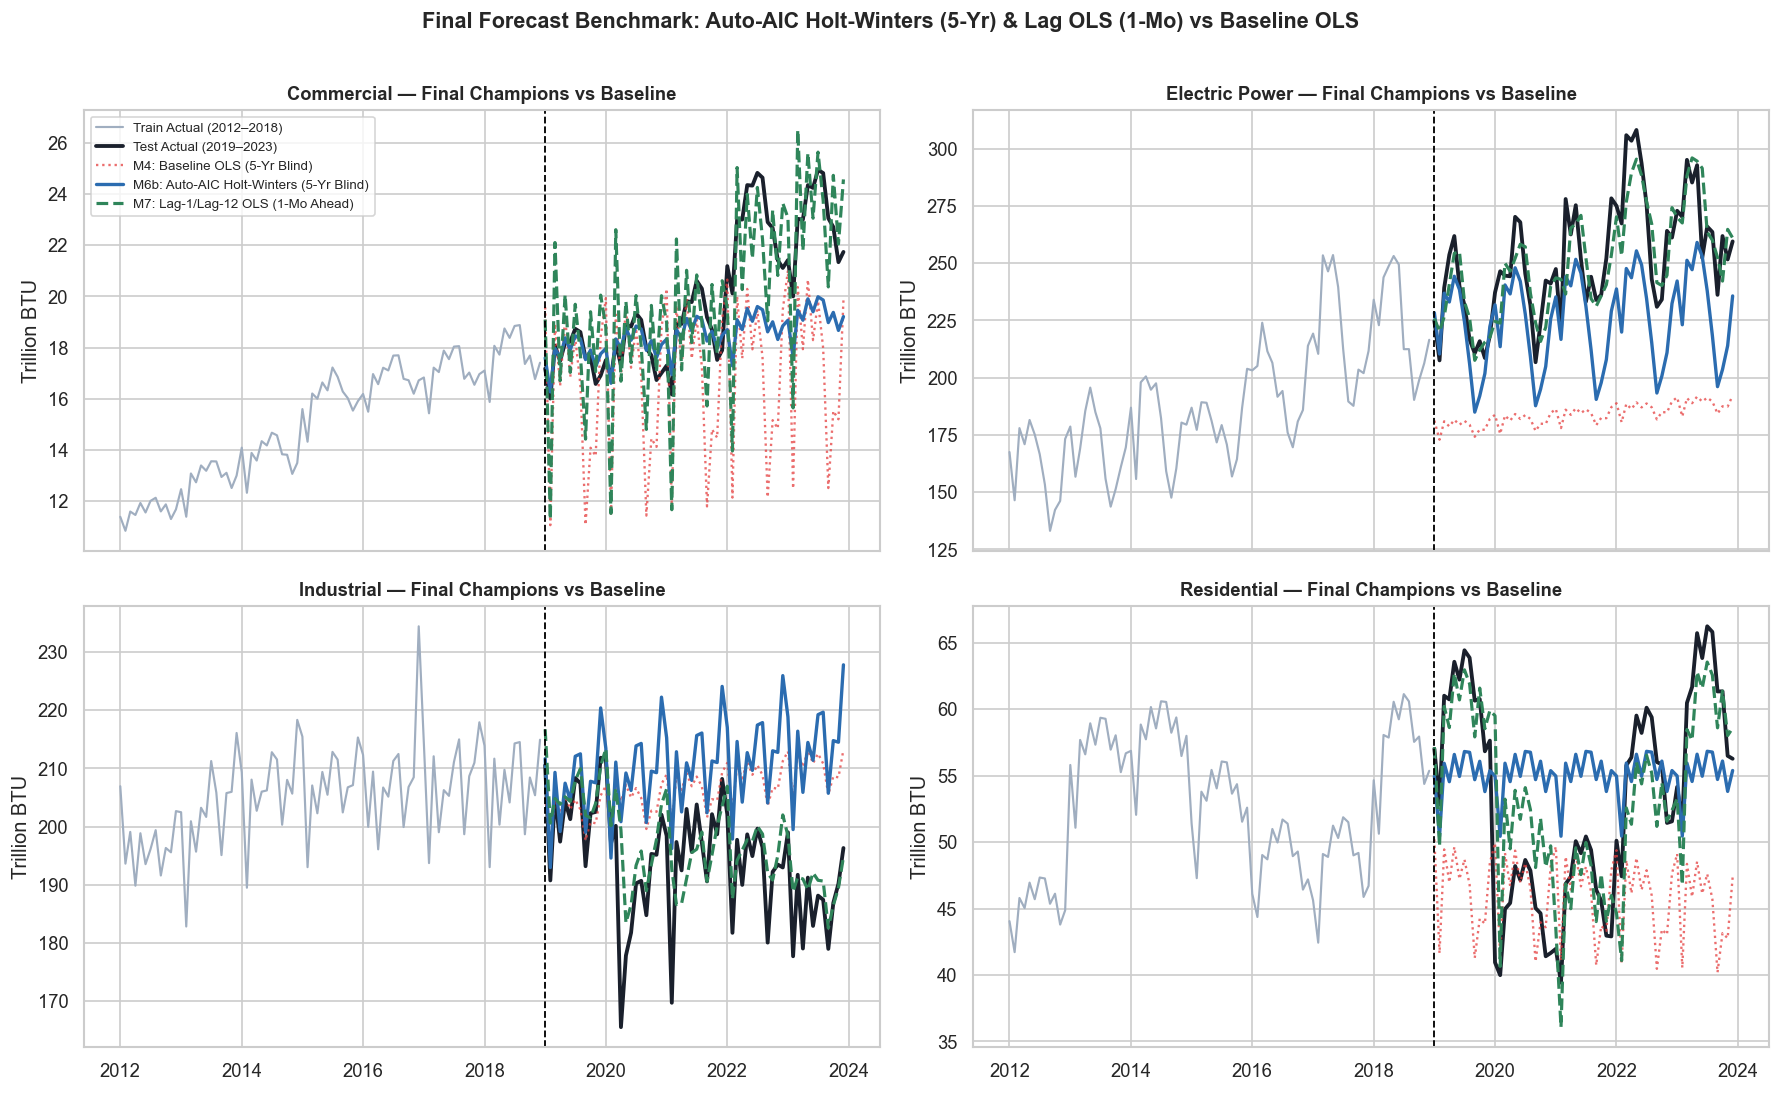

In [101]:
# Align Model 6b (meta_test order) and Model 7 (df_lag order) safely via Year-Month-Sector merge
te_plot = meta_test.copy()
te_plot['Date'] = pd.to_datetime(dict(year=te_plot['Year'], month=te_plot['Month'], day=1))
te_plot['M4_Baseline'] = ols_model.predict(X_test_const).values
te_plot['M6b_HW_AIC'] = pred_hw_aic

m7_df = df_lag.loc[te_idx, ['Year', 'Month', 'Sector']].copy()
m7_df['M7_Lag_OLS'] = pred_m7
te_plot = te_plot.merge(m7_df, on=['Year', 'Month', 'Sector'], how='left')

assert len(te_plot) == 240 and not te_plot['M7_Lag_OLS'].isna().any(), "Merge alignment error!"

hist_plot = meta_train[meta_train['Year'] >= 2012].copy()
hist_plot['Date'] = pd.to_datetime(dict(year=hist_plot['Year'], month=hist_plot['Month'], day=1))

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
for ax, sec in zip(axes.flatten(), sorted(te_plot['Sector'].unique())):
    h = hist_plot[hist_plot['Sector'] == sec].sort_values('Date')
    t = te_plot[te_plot['Sector'] == sec].sort_values('Date')

    ax.plot(h['Date'], h['Total Renewable Energy'], color='#a0aec0', linewidth=1.3, label='Train Actual (2012–2018)')
    ax.plot(t['Date'], t['Total Renewable Energy'], color='#1a202c', linewidth=2.3, label='Test Actual (2019–2023)')
    ax.plot(t['Date'], t['M4_Baseline'], color='#e53e3e', linestyle=':', linewidth=1.4, alpha=0.75, label='M4: Baseline OLS (5-Yr Blind)')
    ax.plot(t['Date'], t['M6b_HW_AIC'], color='#2b6cb0', linestyle='-', linewidth=2.0, label='M6b: Auto-AIC Holt-Winters (5-Yr Blind)')
    ax.plot(t['Date'], t['M7_Lag_OLS'], color='#2f855a', linestyle='--', linewidth=1.9, label='M7: Lag-1/Lag-12 OLS (1-Mo Ahead)')

    ax.axvline(pd.Timestamp('2019-01-01'), color='black', linestyle='--', linewidth=1.1)
    ax.set_title(f"{sec} — Final Champions vs Baseline", fontweight='bold', fontsize=11)
    ax.set_ylabel('Trillion BTU')

    if ax is axes[0, 0]:
        ax.legend(loc='upper left', fontsize=8, frameon=True)

fig.suptitle('Final Forecast Benchmark: Auto-AIC Holt-Winters (5-Yr) & Lag OLS (1-Mo) vs Baseline OLS', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_final_models_forecast.png', dpi=150, bbox_inches='tight')
plt.show()

### 7. Penerjemahan Bisnis & Kebijakan, *Master Leaderboard*, & Ekspor Artefak
**Tujuan:** Merangkum seluruh model pembanding ke dalam satu tabel *leaderboard* yang terstandardisasi, memverifikasi perbaikan autokorelasi residual (*Durbin-Watson within-sector*) pada `Model 7`, menghitung metrik operasional beban puncak vs terendah (`2019–2023`) per sektor bagi pemangku kepentingan jaringan & kebijakan, serta mengekspor tabel ringkasan ke `outputs/`.

In [102]:
OUTPUTS_DIR = Path('../outputs')
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Master Benchmark Leaderboard
master_leaderboard = pd.DataFrame([
    {'Model': 'Seasonal Naive (2018 Repeat)', 'Horizon': '5-Yr Blind', 'Test R²': round(r2_score(y_test, pred_naive), 4), 'Test RMSE': round(np.sqrt(mean_squared_error(y_test, pred_naive)), 2), 'Test MAPE (%)': round(np.mean(np.abs((y_test - pred_naive) / y_test)) * 100, 2)},
    {'Model': 'Model 4: Baseline OLS', 'Horizon': '5-Yr Blind', 'Test R²': round(r2_score(y_test, preds_test['Model 4: Baseline OLS']), 4), 'Test RMSE': round(np.sqrt(mean_squared_error(y_test, preds_test['Model 4: Baseline OLS'])), 2), 'Test MAPE (%)': round(np.mean(np.abs((y_test - preds_test['Model 4: Baseline OLS']) / y_test)) * 100, 2)},
    {'Model': 'Model 5: Improved OLS (Sec×t² + Sec×Mo)', 'Horizon': '5-Yr Blind', 'Test R²': round(r2_score(y_test, pred_m5), 4), 'Test RMSE': round(np.sqrt(mean_squared_error(y_test, pred_m5)), 2), 'Test MAPE (%)': round(np.mean(np.abs((y_test - pred_m5) / y_test)) * 100, 2)},
    {'Model': 'Model 6: Holt-Winters (All Damped)', 'Horizon': '5-Yr Blind', 'Test R²': round(r2_score(y_test, pred_hw), 4), 'Test RMSE': round(np.sqrt(mean_squared_error(y_test, pred_hw)), 2), 'Test MAPE (%)': round(np.mean(np.abs((y_test - pred_hw) / y_test)) * 100, 2)},
    {'Model': 'Model 6b: Auto-AIC Holt-Winters [5-Yr Winner]', 'Horizon': '5-Yr Blind', 'Test R²': round(r2_score(y_test, pred_hw_aic), 4), 'Test RMSE': round(np.sqrt(mean_squared_error(y_test, pred_hw_aic)), 2), 'Test MAPE (%)': round(np.mean(np.abs((y_test - pred_hw_aic) / y_test)) * 100, 2)},
    {'Model': 'Model 7: Lag-1/Lag-12 OLS [1-Mo Winner]', 'Horizon': '1-Mo Ahead', 'Test R²': round(r2_score(y_m7_test, pred_m7), 4), 'Test RMSE': round(np.sqrt(mean_squared_error(y_m7_test, pred_m7)), 2), 'Test MAPE (%)': round(np.mean(np.abs((y_m7_test - pred_m7) / y_m7_test)) * 100, 2)},
])
master_leaderboard['Passes SMART (<10% MAPE & <=40 RMSE)'] = (
    (master_leaderboard['Test MAPE (%)'] < 10.0) & (master_leaderboard['Test RMSE'] <= 40.0)
)

# 2. Check whether Lag features resolve residual autocorrelation in Model 7
m7_resid = m7_lag.resid.values
m7_dw = {
    sec: round(durbin_watson(m7_resid[(df_lag.loc[tr_idx, 'Sector'] == sec).values]), 3)
    for sec in sorted(df_lag['Sector'].unique())
}

# 3. Stakeholder Operational & Policy Reference (Recent 2019–2023 Actuals)
recent_df = df_clean[df_clean['Year'] >= 2019].copy()
total_recent = recent_df['Total Renewable Energy'].sum()

stakeholder_rows = []
for sec, grp in recent_df.groupby('Sector'):
    monthly_avg = grp.groupby('Month')['Total Renewable Energy'].mean()
    peak_m, peak_val = int(monthly_avg.idxmax()), monthly_avg.max()
    low_m, low_val = int(monthly_avg.idxmin()), monthly_avg.min()
    y2019 = grp[grp['Year'] == 2019]['Total Renewable Energy'].sum()
    y2023 = grp[grp['Year'] == 2023]['Total Renewable Energy'].sum()
    stakeholder_rows.append({
        'Sector': sec,
        '2019–2023 Share (%)': round(grp['Total Renewable Energy'].sum() / total_recent * 100, 1),
        'Mean Monthly (BTU)': round(grp['Total Renewable Energy'].mean(), 2),
        '2019→2023 Growth (%)': round((y2023 - y2019) / y2019 * 100, 1),
        'Peak Month': peak_m,
        'Peak Avg (BTU)': round(peak_val, 2),
        'Off-Peak Month': low_m,
        'Off-Peak Avg (BTU)': round(low_val, 2),
        'Seasonal Swing (BTU)': round(peak_val - low_val, 2),
    })

stakeholder_df = pd.DataFrame(stakeholder_rows).sort_values('2019–2023 Share (%)', ascending=False).reset_index(drop=True)

master_leaderboard.to_csv(OUTPUTS_DIR / 'model_benchmark_2019_2023.csv', index=False)
stakeholder_df.to_csv(OUTPUTS_DIR / 'sector_seasonal_planning.csv', index=False)

print("=== Master Model Leaderboard (Out-of-Time 2019–2023) ===")
display(master_leaderboard)
print("Model 7 Within-Sector Durbin-Watson (target ~ 2.0):", m7_dw)
print("\n=== Stakeholder Operational & Policy Reference (2019–2023 Actuals) ===")
display(stakeholder_df)

=== Master Model Leaderboard (Out-of-Time 2019–2023) ===


,Model,Horizon,Test R²,Test RMSE,Test MAPE (%),Passes SMART (<10% MAPE & <=40 RMSE)
0,Seasonal Naive (2018 Repeat),5-Yr Blind,0.9595,19.56,10.58,False
1,Model 4: Baseline OLS,5-Yr Blind,0.8544,37.08,16.60,False
2,Model 5: Improved OLS (Sec×t² + Sec×Mo),5-Yr Blind,0.9419,23.42,15.54,False
3,Model 6: Holt-Winters (All Damped),5-Yr Blind,0.9491,21.93,10.59,False
4,Model 6b: Auto-AIC Holt-Winters [5-Yr Winner],5-Yr Blind,0.9621,18.92,10.10,False
5,Model 7: Lag-1/Lag-12 OLS [1-Mo Winner],1-Mo Ahead,0.9925,8.41,5.97,True


Model 7 Within-Sector Durbin-Watson (target ~ 2.0): {'Commercial': np.float64(2.972), 'Electric Power': np.float64(1.278), 'Industrial': np.float64(2.106), 'Residential': np.float64(1.073)}

=== Stakeholder Operational & Policy Reference (2019–2023 Actuals) ===


,Sector,2019–2023 Share (%),Mean Monthly (BTU),2019→2023 Growth (%),Peak Month,Peak Avg (BTU),Off-Peak Month,Off-Peak Avg (BTU),Seasonal Swing (BTU)
0,Electric Power,48.5,251.91,17.5,5,281.68,9,223.72,57.97
1,Industrial,37.4,194.22,-7.6,1,204.33,2,183.39,20.94
2,Residential,10.3,53.27,0.4,7,57.97,2,46.21,11.76
3,Commercial,3.9,20.00,30.0,7,21.69,2,17.83,3.86


---

### 8. Konklusi Akhir (*Evaluasi, Makna Dunia Nyata, Rekomendasi & Keterbatasan*)

#### A. Pemilihan Model Terbaik & Jawaban Atas Pertanyaan Bisnis
Berdasarkan eksperimen *Out-of-Time* pada periode uji `2019–2023` (`240` observasi bulanan), performa model ditentukan oleh horizon peramalan yang digunakan:
1. **Model Strategis Jangka Panjang (5 Tahun Buta / *60-Step Blind Forecast*): `Model 6b (Auto-AIC Holt-Winters ETS)`**
   - Mencapai **$R^2 = 0.9621$**, **$\text{RMSE} = 18.92\text{ Trillion BTU}$**, dan **$\text{MAPE} = 10.10\%$** — mengungguli seluruh model statis (`Model 4` MAPE `16.60%`, `Model 5` Kuadratik `15.54%`) maupun tolok ukur *Seasonal Naive* (`10.58%`), dan hanya terpaut `0.10` poin persentase dari batas `<10%`. Ini menegaskan bahwa adaptivitas tren lokal + musiman multiplikatif/aditif per sektor krusial untuk proyeksi jangka panjang.
2. **Model Operasional Jangka Pendek (1 Bulan ke Depan / *1-Month Ahead*): `Model 7 (Lag-1 / Lag-12 OLS)`**
   - Memenuhi **seluruh kriteria SMART** dengan **$R^2 = 0.9925$**, **$\text{RMSE} = 8.41\text{ Trillion BTU}$**, dan **$\text{MAPE} = 5.97\% < 10\%$** (`Electric Power` turun drastis ke `4.38%`, `Industrial` `2.64%`, `Residential` `6.30%`, `Commercial` `10.55%`), sekaligus memperbaiki masalah autokorelasi *within-sector* (terutama `Industrial` $\text{DW} = 2.106$ dan `Commercial` $\text{DW} = 2.972$ dibanding `Model 4` sebelumnya yang `0.39` & `1.491`).
   - *Catatan keselarasan metode regresi:* Selain mengandalkan fitur eksogen waktu/sektor (`Model 1–5`), penggunaan fitur *autoregressive* historis `lag_1`, `lag_12`, dan `ma_12` di dalam kerangka **Multiple Linear Regression (`Model 7`)** menjadi kunci untuk menerjemahkan korelasi serial data energi menjadi prediksi operasional yang akurat tanpa kebocoran data masa depan.

#### B. Penerjemahan Metrik ke Makna Dunia Nyata (*Real-World Impact*) & Rekomendasi Kebijakan
- **Skala Error Fisik:** Nilai $\text{RMSE} = 8.41\text{ Trillion BTU}$ pada `Model 7` (atau `18.92 Trillion BTU` pada `Model 6b`) setara dengan fluktuasi kurang dari `~3–8%` terhadap rata-rata konsumsi bulanan sektor terbesar (`Electric Power = 251.91`, `Industrial = 194.22 Trillion BTU`), cukup presisi untuk penyusunan anggaran operasional bulanan dan manajemen cadangan daya (*reserve margin*).
- **Penjadwalan Pemeliharaan Jaringan (*Grid Maintenance*) & PPA (`Electric Power` — Pangsa `48.5%`, Tumbuh `+17.5%`):**
  - Puncak beban rata-rata `2019–2023` jatuh pada bulan **Mei (`281.68 Trillion BTU`)**, lalu turun tajam ke titik terendah pada bulan **September (`223.72 Trillion BTU`)** dengan ayunan musiman sebesar **`57.97 Trillion BTU`**. Operator jaringan direkomendasikan menjadwalkan pemeliharaan rutin pembangkit/transmisi pada **September** dan memastikan kecukupan kapasitas cadangan serta kontrak *Power Purchase Agreement* menjelang lonjakan **Mei**.
- **Strategi Sektor Industri, Residensial & Komersial:**
  - `Industrial` (`37.4%` pangsa, perubahan `-7.6%`) cenderung stabil sepanjang tahun (puncak Jan `204.33`, terendah Feb `183.39`).
  - `Commercial` (`3.9%` pangsa) menunjukkan pertumbuhan relatif tertinggi (**`+30.0%`** pada `2019–2023`), sedangkan `Residential` (`10.3%` pangsa, `+0.4%`) memuncak pada bulan **Juli (`57.97 Trillion BTU`)** dan melandai pada **Februari (`46.21 Trillion BTU`)**. Regulator dapat memfokuskan insentif energi surya/efisiensi bangunan untuk mempercepat adopsi di sektor komersial dan residensial menjelang beban puncak musim panas (Juli).

#### C. Keterbatasan Penelitian (*Limitations*)
1. **Tidak Ada Variabel Eksogen Eksternal:** Model hanya memanfaatkan dimensi waktu (`t`, `Month`, *lag*) dan `Sector` tanpa memasukkan faktor eksternal seperti suhu ekstrem/curah hujan, harga bahan bakar fosil, maupun kebijakan subsidi energi (*Inflation Reduction Act*), sehingga lonjakan mendadak akibat guncangan kebijakan atau cuaca belum dapat dijelaskan secara kausal.
2. **Agregasi Nasional AS & Efek Kalender:** Data bersifat agregat tingkat nasional Amerika Serikat (bukan granularitas per negara bagian) dan menyajikan total konsumsi bulanan mentah tanpa normalisasi jumlah hari per bulan (`28/29` hari di Februari vs `30/31` hari di bulan lain).
3. **Evaluasi *Auto-AIC Holt-Winters* vs *Regression Lag*:** `Model 7` membutuhkan nilai aktual bulan sebelumnya ($t-1$ dan $t-12$) saat dioperasikan sehingga berlaku untuk horizon **1 bulan ke depan**, sementara proyeksi multi-tahun tanpa observasi baru mengandalkan `Model 6b` yang berada tipis di `10.10%` MAPE.